<a href="https://colab.research.google.com/github/anasarshad7677-netizen/Complete-ML-repo/blob/main/16_handling_missing_values.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection  import train_test_split

In [4]:
df = pd.read_csv("/content/data_science_job (1).csv")

In [5]:
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,NaN,NaN,36.0,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15.0,50-99,Pvt Ltd,47.0,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5.0,NaN,NaN,83.0,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,0.0,NaN,Pvt Ltd,52.0,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,20.0,50-99,Funded Startup,8.0,0.0


In [6]:
df.isnull().mean()*100

,0
enrollee_id,0.000000
city,0.000000
city_development_index,2.500261
gender,23.530640
relevent_experience,0.000000
enrolled_university,2.014824
education_level,2.401086
major_discipline,14.683161
experience,0.339284
company_size,30.994885


In [7]:
df.shape


(19158, 13)

In [8]:
cols = [var for var in df.columns if df[var].isnull().mean()<0.05 and df[var].isnull().mean()>0]
cols

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

In [9]:
df[cols].sample(5)

,city_development_index,enrolled_university,education_level,experience,training_hours
5510,0.923,no_enrollment,Phd,7.0,26.0
10364,0.925,no_enrollment,Masters,13.0,39.0
2137,0.920,no_enrollment,Graduate,4.0,39.0
9167,0.899,no_enrollment,Graduate,8.0,61.0
5009,0.910,no_enrollment,Masters,8.0,74.0


In [10]:
len(df[cols].dropna())/len(df)

0.8968577095730244

In [11]:
new_df = df[cols].dropna()
df.shape,new_df.shape

((19158, 13), (17182, 5))

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [13]:
df = pd.read_csv('/content/titanic_toy.csv')

In [14]:
df.isnull().mean()

,0
Age,0.198653
Fare,0.050505
Family,0.000000
Survived,0.000000


In [15]:
x = df.drop(columns = ['Survived'])
y = df['Survived']

In [39]:
x_train,x_test,y_train,y_test = train_test_split(
    x,y,
    test_size = 0.2,
    random_state = 42
)

In [17]:
x_train.shape

(712, 3)

In [18]:
x_test.shape

(179, 3)

In [19]:
x_train.isnull().mean()

,0
Age,0.196629
Fare,0.050562
Family,0.000000


In [20]:
mean_age = x_train['Age'].mean()
median_age = x_train['Age'].median()

mean_fare = x_train['Fare'].mean()
median_fare = x_train['Fare'].median()

In [22]:
x_train['mean_age']=x_train['Age'].fillna(mean_age)
x_train['median_age']=x_train['Age'].fillna(median_age)
x_train['mean_fare']=x_train['Fare'].fillna(mean_fare)
x_train['median_fare']=x_train['Fare'].fillna(median_fare)


In [25]:
x_train.sample(10)

,Age,Fare,Family,mean_age,median_age,mean_fare,median_fare
846,NaN,69.5500,10,29.498846,28.0,69.550000,69.5500
520,30.0,NaN,0,30.000000,30.0,32.517788,14.4000
62,45.0,83.4750,1,45.000000,45.0,83.475000,83.4750
718,NaN,15.5000,0,29.498846,28.0,15.500000,15.5000
265,36.0,10.5000,0,36.000000,36.0,10.500000,10.5000
271,25.0,NaN,0,25.000000,25.0,32.517788,14.4000
703,25.0,7.7417,0,25.000000,25.0,7.741700,7.7417
314,43.0,26.2500,2,43.000000,43.0,26.250000,26.2500
504,16.0,86.5000,0,16.000000,16.0,86.500000,86.5000
45,NaN,8.0500,0,29.498846,28.0,8.050000,8.0500


In [29]:
print(f"this is the actual")
print(f"this is variance  the mean fare of titanic     {x_train['mean_fare'].var()}")
print(f"this is  variance the median fare of titanic   {x_train['median_fare'].var()}")
print(f"this is variance  the mean age of titanic      {x_train['mean_age'].var()}")
print(f"this is  variance the median age of titanic    {x_train['median_age'].var()}")

this is the actual
this is variance  the mean fare of titanic     2621.2323749512393
this is  variance the median fare of titanic   2637.01248167777
this is variance  the mean age of titanic      168.8519336687225
this is  variance the median age of titanic    169.20731007048096


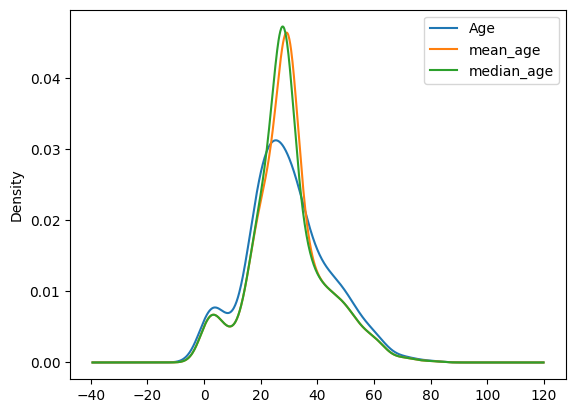

In [31]:
fig = plt.figure()
ax = fig.add_subplot(111)

x_train['Age'].plot(kind='kde',ax=ax)

x_train['mean_age'].plot(kind='kde',ax=ax)

x_train['median_age'].plot(kind='kde',ax=ax)
lines , labels = ax.get_legend_handles_labels()
ax.legend (lines,labels,loc='best')


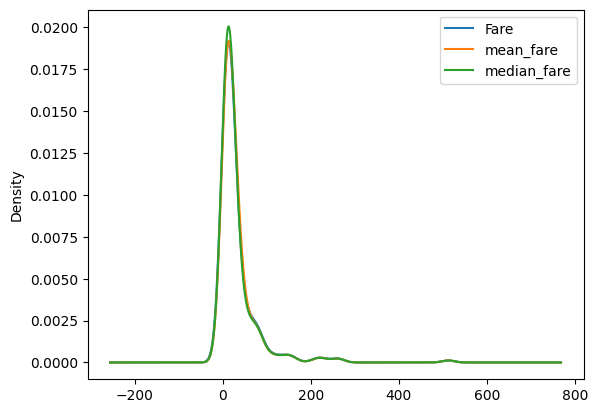

In [32]:
fig = plt.figure()
ax = fig.add_subplot(111)

x_train['Fare'].plot(kind='kde',ax=ax)

x_train['mean_fare'].plot(kind='kde',ax=ax)

x_train['median_fare'].plot(kind='kde',ax=ax)
lines , labels = ax.get_legend_handles_labels()
ax.legend (lines,labels,loc='best')


<Axes: >

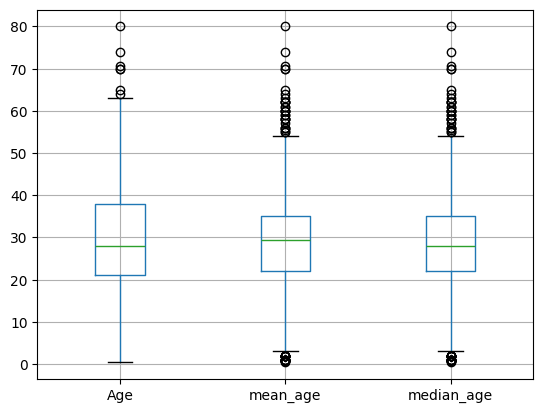

In [34]:
x_train[['Age','mean_age','median_age']].boxplot()

<Axes: >

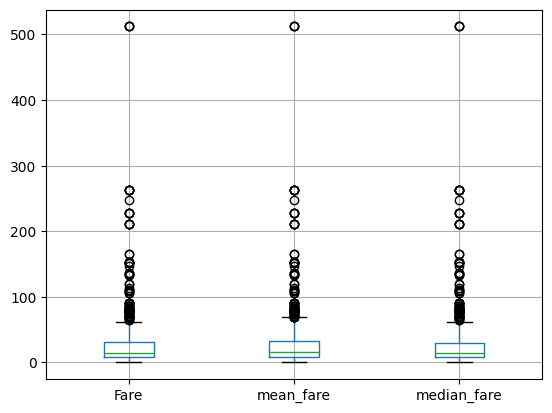

In [35]:
x_train[['Fare','mean_fare','median_fare']].boxplot()

In [40]:
imputer1 = SimpleImputer(strategy='mean')
imputer2 = SimpleImputer(strategy='median')

In [44]:
pipe = ColumnTransformer(
    [
('imputer',imputer1,['Age']),
('imputer2',imputer2,['Fare'])
    ],remainder= 'passthrough'
)

In [45]:
pipe.fit(x_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


ColumnTransformer(remainder='passthrough',
                  transformers=[('imputer', SimpleImputer(), ['Age']),
                                ('imputer2', SimpleImputer(strategy='median'),
                                 ['Fare'])])

In [46]:
pipe.fit_transform(x_train)

array([[ 45.5   ,  28.5   ,   0.    ],
       [ 23.    ,  13.    ,   0.    ],
       [ 32.    ,   7.925 ,   0.    ],
       ...,
       [ 41.    ,  14.4   ,   2.    ],
       [ 14.    , 120.    ,   3.    ],
       [ 21.    ,  77.2875,   1.    ]])

In [48]:
pipe.fit_transform(x_test)

array([[ 30.50584507,  15.2458    ,   2.        ],
       [ 31.        ,  10.5       ,   0.        ],
       [ 20.        ,   7.925     ,   0.        ],
       [  6.        ,  33.        ,   1.        ],
       [ 14.        ,  11.2417    ,   1.        ],
       [ 26.        ,  78.85      ,   0.        ],
       [ 30.50584507,   7.75      ,   0.        ],
       [ 16.        ,  18.        ,   2.        ],
       [ 16.        ,   7.75      ,   0.        ],
       [ 19.        ,  26.2833    ,   2.        ],
       [ 37.        ,  53.1       ,   1.        ],
       [ 44.        ,   8.05      ,   0.        ],
       [ 30.50584507,  25.4667    ,   4.        ],
       [ 30.        ,   7.225     ,   0.        ],
       [ 36.        ,  13.        ,   0.        ],
       [ 16.        ,  39.4       ,   1.        ],
       [ 42.        ,  52.5542    ,   1.        ],
       [ 30.50584507,   7.8292    ,   0.        ],
       [ 27.        ,  13.        ,   0.        ],
       [ 47.        ,  52.     